# Extended Data Figure 1: Recognition and architecture selection

Run all cells from the notebook directory. The supplied replicate-level CSV is used by default. Set `RECOMPUTE=True` to regenerate the 5,880 simulations and extend unresolved cases. Dependencies: NumPy, pandas, Numba, and Matplotlib.

## Configuration

In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from typing import Tuple
import csv
import json
import sys
import time

import numpy as np
import pandas as pd
from numba import njit
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

ROOT = Path.cwd()
OUT = ROOT / 'data' / 'extended_data_figure1'
FIGURES = ROOT / 'figures' / 'extended_data_figure1'
OUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False

CFG = dict(
    N=150, repetitions=30, sweeps=1000, burnin=800, interval=5,
    base_seed=20260918, e1=.02, e2=.02, alpha=1., beta=1.,
    k_min=0, k_max=6, workers=6,
)
VERSION = 'recognition-selection-direct-reset-v1-20260919'
NORMS = {'SC': (1., 0.), 'SH': (0., 0.), 'SJ': (0., 1.), 'SS': (1., 1.)}
NORM_NAMES = {'SC': 'Scoring', 'SH': 'Shunning',
              'SJ': 'Stern Judging', 'SS': 'Simple Standing'}
REPRESENTATIVE = {'SC': (2, 0), 'SH': (3, 0), 'SJ': (4, 3), 'SS': (1, 2)}
METRICS = ['g_DISC', 'g_ALLC', 'g_ALLD',
           'disagreement_DISC', 'disagreement_ALLC', 'disagreement_ALLD',
           'warning_fraction', 'suspicious_fraction']
assert CFG['N'] % 3 == 0 and CFG['N'] >= 6
assert CFG['repetitions'] >= 2 and CFG['workers'] >= 1
assert 0 <= CFG['burnin'] < CFG['sweeps'] and CFG['interval'] >= 1
assert (CFG['sweeps'] - CFG['burnin']) // CFG['interval'] >= 2
assert (CFG['k_min'], CFG['k_max']) == (0, 6)
assert 0 <= CFG['e1'] < .5 and 0 <= CFG['e2'] < .5
assert 0 <= CFG['alpha'] <= 1 and 0 <= CFG['beta'] <= 1

def write_csv(path, rows):
    rows = list(rows)
    if not rows:
        return
    fields = list(dict.fromkeys((key for row in rows for key in row)))
    with Path(path).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

def provenance(**values):
    base = dict(model_version=VERSION, norm='not_applicable', k1='not_applicable', k2='not_applicable', alpha=CFG['alpha'], beta=CFG['beta'], e1=CFG['e1'], e2=CFG['e2'], N=CFG['N'], seed=CFG['base_seed'], repetitions=CFG['repetitions'], convergence_flag='not_evaluated', residual='not_applicable', branch_selection_method='all_good_internal_state')
    base.update(values)
    return base

## Private reputation dynamics

Assessments use direct reset and independently sampled binary readouts. Strategies have equal population counts and remain fixed.

In [2]:
def build_direct_reset_transitions(k1: int, k2: int) -> Tuple[np.ndarray, np.ndarray]:
    """Build positive/negative transition tables, allowing depth zero."""
    if k1 < 0 or k2 < 0:
        raise ValueError('k1 and k2 must be non-negative.')
    b_index = k1 + 1
    n_states = k1 + k2 + 2
    positive = np.empty(n_states, dtype=np.int16)
    negative = np.empty(n_states, dtype=np.int16)
    positive[0] = 0
    negative[0] = 1 if k1 > 0 else b_index
    for m in range(1, k1 + 1):
        positive[m] = 0
        negative[m] = m + 1 if m < k1 else b_index
    positive[b_index] = b_index + 1 if k2 > 0 else 0
    negative[b_index] = b_index
    for n in range(1, k2 + 1):
        state = b_index + n
        positive[state] = state + 1 if n < k2 else 0
        negative[state] = b_index
    return (positive, negative)

@njit(cache=False, nogil=True)
def _binary_draw(probability: float) -> int:
    return 1 if np.random.random() < probability else 0

@njit(cache=False, nogil=True)
def _accumulate_statistics(latent: np.ndarray, sigma: np.ndarray, n_disc: int, n_allc: int, k1: int, accumulator: np.ndarray) -> None:
    """Add one instantaneous measurement to the accumulator."""
    population_size = latent.shape[1]
    starts = (0, n_disc, n_disc + n_allc)
    ends = (n_disc, n_disc + n_allc, population_size)
    for group in range(3):
        sum_target_goodness = 0.0
        sum_target_disagreement = 0.0
        n_targets = ends[group] - starts[group]
        for target in range(starts[group], ends[group]):
            sum_s = 0.0
            sum_s2 = 0.0
            for observer in range(n_disc):
                value = sigma[latent[observer, target]]
                sum_s += value
                sum_s2 += value * value
            sum_target_goodness += sum_s / n_disc
            numerator = (n_disc - 1.0) * sum_s - (sum_s * sum_s - sum_s2)
            denominator = 0.5 * n_disc * (n_disc - 1.0)
            sum_target_disagreement += numerator / denominator
        accumulator[group] += sum_target_goodness / n_targets
        accumulator[3 + group] += sum_target_disagreement / n_targets
    b_index = k1 + 1
    warning_count = 0
    suspicious_count = 0
    for observer in range(latent.shape[0]):
        for target in range(latent.shape[1]):
            state = latent[observer, target]
            if 1 <= state < b_index:
                warning_count += 1
            elif state > b_index:
                suspicious_count += 1
    n_records = latent.shape[0] * latent.shape[1]
    accumulator[6] += warning_count / n_records
    accumulator[7] += suspicious_count / n_records

@njit(cache=False, nogil=True)
def _simulate_replicate(n_disc: int, n_allc: int, n_alld: int, p_norm: float, q_norm: float, e1: float, e2: float, k1: int, sigma: np.ndarray, positive: np.ndarray, negative: np.ndarray, total_events: int, burnin_events: int, interval_events: int, use_seed: bool, seed: int) -> Tuple[np.ndarray, int, np.ndarray, np.ndarray]:
    if use_seed:
        np.random.seed(seed)
    population_size = n_disc + n_allc + n_alld
    latent = np.zeros((n_disc, population_size), dtype=np.int16)
    accumulator = np.zeros(8, dtype=np.float64)
    n_samples = 0
    samples = np.zeros((1 + (total_events - burnin_events) // interval_events, 8))
    next_sample = burnin_events
    for event in range(total_events):
        donor = np.random.randint(0, population_size)
        recipient = np.random.randint(0, population_size - 1)
        if recipient >= donor:
            recipient += 1
        observer = np.random.randint(0, n_disc)
        if donor < n_disc:
            intended_cooperation = _binary_draw(sigma[latent[donor, recipient]])
        elif donor < n_disc + n_allc:
            intended_cooperation = 1
        else:
            intended_cooperation = 0
        realized_cooperation = intended_cooperation
        if intended_cooperation == 1 and np.random.random() < e1:
            realized_cooperation = 0
        recipient_good = _binary_draw(sigma[latent[observer, recipient]])
        if realized_cooperation == 1:
            positive_probability = 1.0 if recipient_good == 1 else p_norm
        else:
            positive_probability = 0.0 if recipient_good == 1 else q_norm
        recorded_positive = _binary_draw(positive_probability)
        if np.random.random() < e2:
            recorded_positive = 1 - recorded_positive
        current = latent[observer, donor]
        latent[observer, donor] = positive[current] if recorded_positive == 1 else negative[current]
        completed_events = event + 1
        if completed_events >= next_sample:
            before = accumulator.copy()
            _accumulate_statistics(latent, sigma, n_disc, n_allc, k1, accumulator)
            samples[n_samples] = accumulator - before
            n_samples += 1
            next_sample += interval_events
    if n_samples > 0:
        accumulator /= n_samples
    return (accumulator, n_samples, samples[:n_samples], latent)

def readout(k1, k2, alpha=1.0, beta=1.0):
    if min(k1, k2) < 0 or not 0 <= alpha <= 1 or (not 0 <= beta <= 1):
        raise ValueError('Invalid depth/readout')
    return np.array([1.0, *[alpha ** m for m in range(1, k1 + 1)], 0.0, *[1 - beta ** m for m in range(1, k2 + 1)]])

def exact_disagreement(weights):
    weights = np.asarray(weights)
    n = len(weights)
    s = weights.sum()
    ss = weights @ weights
    if n < 2:
        raise ValueError('Two distinct observers required')
    return ((n - 1) * s - s * s + ss) / (n * (n - 1) / 2)

def self_check():
    for k1, k2 in [(0, 0), (1, 1), (2, 0), (3, 0), (4, 3), (1, 2)]:
        positive, negative = build_direct_reset_transitions(k1, k2)
        assert len(positive) == len(negative) == k1 + k2 + 2
        assert np.all((positive >= 0) & (positive < len(positive)))
        assert np.all((negative >= 0) & (negative < len(negative)))
    for weights in [np.array([0.0, 1.0, 1.0]), np.array([0.1, 0.4, 0.8, 1.0])]:
        pairs = [weights[i] * (1 - weights[j]) + (1 - weights[i]) * weights[j] for i in range(len(weights)) for j in range(i + 1, len(weights))]
        assert abs(exact_disagreement(weights) - np.mean(pairs)) < 1e-14
    print('Direct-reset transitions and exact finite-observer disagreement checks passed.')

self_check()

Direct-reset transitions and exact finite-observer disagreement checks passed.


## Simulation and statistical analysis

In [3]:
def simulate_task(task):
    norm, k1, k2, replicate = task
    n = CFG['N'] // 3
    events_per_sweep = n * CFG['N']
    seed = int(np.random.SeedSequence([CFG['base_seed'], list(NORMS).index(norm), k1, k2, replicate]).generate_state(1)[0])
    positive, negative = build_direct_reset_transitions(k1, k2)
    weights = readout(k1, k2, CFG['alpha'], CFG['beta'])
    values, n_samples, trace, _ = _simulate_replicate(n, n, n, *NORMS[norm], CFG['e1'], CFG['e2'], k1, weights, positive, negative, CFG['sweeps'] * events_per_sweep, CFG['burnin'] * events_per_sweep, CFG['interval'] * events_per_sweep, True, seed)
    separation = 0.5 * (trace[:, 0] + trace[:, 1]) - trace[:, 2]
    disagreement = trace[:, 3:6].mean(axis=1)
    half = n_samples // 2
    row = provenance(norm=norm, k1=k1, k2=k2, seed=seed, replicate=replicate, n_samples=n_samples, convergence_flag='assessed_across_replicates', **dict(zip(METRICS, map(float, values))), separation=float(separation.mean()), disagreement=float(disagreement.mean()), separation_half_drift=float(separation[half:].mean() - separation[:half].mean()), disagreement_half_drift=float(disagreement[half:].mean() - disagreement[:half].mean()), sweep_count=CFG['sweeps'], burnin=CFG['burnin'], interval=CFG['interval'])
    directory = OUT / ('replicates' if CFG['sweeps'] == 1000 else f"replicates_{CFG['sweeps']}")
    directory.mkdir(exist_ok=True)
    stem = directory / f'{norm}_{k1}_{k2}_{replicate:02d}'
    stem.with_suffix('.json').write_text(json.dumps(row, indent=2), encoding='utf-8')
    np.savez_compressed(stem.with_suffix('.npz'), measurements=trace)
    return row

def run_full_grid():
    pairs = [(k1, k2) for k1 in range(7) for k2 in range(7)]
    tasks = [(norm, k1, k2, replicate) for norm in NORMS for k1, k2 in pairs for replicate in range(CFG['repetitions'])]
    first = simulate_task(tasks[0])
    rows = [first]
    started = time.time()
    with ThreadPoolExecutor(max_workers=CFG['workers']) as pool:
        futures = [pool.submit(simulate_task, task) for task in tasks[1:]]
        for future in as_completed(futures):
            rows.append(future.result())
            if len(rows) % 150 == 0:
                print(f'{len(rows)}/{len(tasks)} replicates; {time.time() - started:.0f}s', flush=True)
    rows.sort(key=lambda row: (row['norm'], row['k1'], row['k2'], row['replicate']))
    write_csv(OUT / 'recognition_raw.csv', rows)
    print(f'Saved {len(rows)} independent replicate rows.')
    return rows

def summarize_recognition(raw):
    summaries = []
    rng = np.random.default_rng(2026091801)
    keys = sorted({(row['norm'], int(row['k1']), int(row['k2'])) for row in raw})
    for norm, k1, k2 in keys:
        rows = [row for row in raw if row['norm'] == norm and int(row['k1']) == k1 and (int(row['k2']) == k2)]
        bootstrap = rng.integers(0, len(rows), (2000, len(rows)))
        summary = provenance(norm=norm, k1=k1, k2=k2, K=k1 + k2, repetitions=len(rows), sweep_count=rows[0]['sweep_count'], burnin=rows[0]['burnin'])
        for metric in METRICS + ['separation', 'disagreement', 'separation_half_drift', 'disagreement_half_drift']:
            values = np.array([float(row[metric]) for row in rows])
            bootstrap_means = values[bootstrap].mean(axis=1)
            summary[metric] = float(values.mean())
            summary[metric + '_se'] = float(values.std(ddof=1) / np.sqrt(len(values)))
            summary[metric + '_lo'], summary[metric + '_hi'] = map(float, np.quantile(bootstrap_means, [0.025, 0.975]))
        summary['convergence_flag'] = all((summary[metric + '_lo'] > -0.01 and summary[metric + '_hi'] < 0.01 for metric in ['separation_half_drift', 'disagreement_half_drift']))
        summaries.append(summary)
    for row in summaries:
        peers = [candidate for candidate in summaries if candidate['norm'] == row['norm'] and candidate['convergence_flag']]
        if not row['convergence_flag']:
            row['pareto'] = False
            row['pareto_with_depth'] = False
            row['pareto_same_K'] = False
            continue
        row['pareto'] = not any((candidate['separation'] >= row['separation'] and candidate['disagreement'] <= row['disagreement'] and (candidate['separation'] > row['separation'] or candidate['disagreement'] < row['disagreement']) for candidate in peers))
        row['pareto_with_depth'] = not any((candidate['K'] <= row['K'] and candidate['separation'] >= row['separation'] and (candidate['disagreement'] <= row['disagreement']) and (candidate['K'] < row['K'] or candidate['separation'] > row['separation'] or candidate['disagreement'] < row['disagreement']) for candidate in peers))
        row['pareto_same_K'] = not any((candidate['K'] == row['K'] and candidate['separation'] >= row['separation'] and (candidate['disagreement'] <= row['disagreement']) and (candidate['separation'] > row['separation'] or candidate['disagreement'] < row['disagreement']) for candidate in peers))
    return summaries

def choose(peers, min_separation=0.8, max_disagreement=0.1, conservative=False):
    qualified = [row for row in peers if row['convergence_flag'] and (row['separation_lo'] if conservative else row['separation']) >= min_separation and ((row['disagreement_hi'] if conservative else row['disagreement']) <= max_disagreement)]
    if not qualified:
        return None
    return min(qualified, key=lambda row: (row['K'], -row['separation'], row['disagreement'], row['k1'], row['k2']))

def extend_drifting_runs(raw):
    write_csv(OUT / 'recognition_raw_initial.csv', raw)
    original = CFG.copy()
    extensions = []
    try:
        for duration in [3000, 10000, 50000]:
            summary = summarize_recognition(raw)
            failed = {(row['norm'], row['k1'], row['k2']) for row in summary if not row['convergence_flag']}
            if not failed:
                break
            CFG['sweeps'] = duration
            CFG['burnin'] = int(0.8 * duration)
            print('Extending small-drift cases to', duration, 'sweeps:', sorted(failed), flush=True)
            tasks = [(*key, replicate) for key in sorted(failed) for replicate in range(CFG['repetitions'])]
            with ThreadPoolExecutor(max_workers=CFG['workers']) as pool:
                extra = list(pool.map(simulate_task, tasks))
            raw = [row for row in raw if (row['norm'], int(row['k1']), int(row['k2'])) not in failed] + extra
            extensions.extend([dict(norm=norm, k1=k1, k2=k2, sweeps=duration, burnin=CFG['burnin']) for norm, k1, k2 in sorted(failed)])
    finally:
        CFG.clear()
        CFG.update(original)
    raw.sort(key=lambda row: (row['norm'], int(row['k1']), int(row['k2']), int(row['replicate'])))
    final_summary = summarize_recognition(raw)
    final_status = {(row['norm'], int(row['k1']), int(row['k2'])): bool(row['convergence_flag']) for row in final_summary}
    unresolved = sorted((key for key, converged in final_status.items() if not converged))
    for row in raw:
        key = (row['norm'], int(row['k1']), int(row['k2']))
        row['architecture_convergence_flag'] = final_status[key]
        row['exclusion_reason'] = '' if final_status[key] else 'final half-window drift criterion not met'
    write_csv(OUT / 'recognition_raw.csv', raw)
    return (raw, extensions, unresolved)

def selection_analysis(raw):
    summary = summarize_recognition(raw)
    assert all((not row['pareto'] and (not row['pareto_with_depth']) and (not row['pareto_same_K']) for row in summary if not row['convergence_flag'])), 'Non-converged architectures must be excluded from non-dominated sets.'
    write_csv(OUT / 'recognition_summary.csv', summary)
    sensitivity = []
    selected = []
    for norm in NORMS:
        peers = [row for row in summary if row['norm'] == norm]
        for conservative in [False, True]:
            for min_separation in [0.7, 0.75, 0.8, 0.85, 0.9]:
                for max_disagreement in [0.05, 0.075, 0.1, 0.125, 0.15]:
                    choice = choose(peers, min_separation, max_disagreement, conservative)
                    sensitivity.append(provenance(norm=norm, k1=choice['k1'] if choice else '', k2=choice['k2'] if choice else '', K=choice['K'] if choice else '', separation_threshold=min_separation, disagreement_threshold=max_disagreement, selection='pointwise_CI' if conservative else 'mean', found=choice is not None, convergence_flag=choice['convergence_flag'] if choice else False, grid_scope='complete_0_to_6'))
        choice = choose(peers)
        conservative_choice = choose(peers, conservative=True)
        reference = next((row for row in peers if (row['k1'], row['k2']) == REPRESENTATIVE[norm]))
        selected.append(provenance(norm=norm, k1=choice['k1'] if choice else '', k2=choice['k2'] if choice else '', K=choice['K'] if choice else '', label='representative architecture', reference_k1=REPRESENTATIVE[norm][0], reference_k2=REPRESENTATIVE[norm][1], matches_current_representative=bool(choice and (choice['k1'], choice['k2']) == REPRESENTATIVE[norm]), ci_selected=f"({conservative_choice['k1']},{conservative_choice['k2']})" if conservative_choice else 'none', separation=choice['separation'] if choice else '', separation_lo=choice['separation_lo'] if choice else '', separation_hi=choice['separation_hi'] if choice else '', disagreement=choice['disagreement'] if choice else '', disagreement_lo=choice['disagreement_lo'] if choice else '', disagreement_hi=choice['disagreement_hi'] if choice else '', reference_separation=reference['separation'], reference_disagreement=reference['disagreement'], convergence_flag=choice['convergence_flag'] if choice else False, operational_criterion='mean separation >= 0.8 and mean disagreement <= 0.1', reason='minimum total depth, then greater separation, lower disagreement, k1, k2'))
    write_csv(OUT / 'threshold_sensitivity.csv', sensitivity)
    write_csv(OUT / 'selected_architectures.csv', selected)
    return (summary, selected)

In [4]:
raw_file = OUT / 'recognition_raw.csv'
config_file = OUT / 'input_config.json'
if RECOMPUTE:
    recognition_raw = run_full_grid()
    recognition_raw, extensions, unresolved = extend_drifting_runs(recognition_raw)
    config_file.write_text(json.dumps(CFG, indent=2) + '\n', encoding='utf-8')
else:
    if not raw_file.is_file() or not config_file.is_file():
        raise FileNotFoundError('Place recognition_raw.csv and input_config.json in data/extended_data_figure1, or set RECOMPUTE=True.')
    saved_config = json.loads(config_file.read_text())
    if any(CFG[key] != saved_config.get(key) for key in CFG if key != 'workers'):
        raise ValueError('The saved data configuration does not match CFG. Set RECOMPUTE=True to regenerate it.')
    recognition_raw = pd.read_csv(raw_file, keep_default_na=False).to_dict('records')
    extensions = []
    unresolved = []

raw_table = pd.DataFrame(recognition_raw)
assert len(raw_table) == len(NORMS) * 49 * CFG['repetitions']
assert not raw_table.duplicated(['norm', 'k1', 'k2', 'replicate']).any()
assert raw_table.groupby(['norm', 'k1', 'k2']).size().eq(CFG['repetitions']).all()
for key in ['N', 'e1', 'e2', 'alpha', 'beta', 'interval']:
    assert np.allclose(raw_table[key].astype(float), CFG[key])
expected_samples = 1 + (raw_table['sweep_count'] - raw_table['burnin']) // raw_table['interval']
assert np.array_equal(raw_table['n_samples'].to_numpy(), expected_samples.to_numpy())
assert (raw_table['burnin'] == (.8 * raw_table['sweep_count']).astype(int)).all()

recognition_summary, selected_rows = selection_analysis(recognition_raw)
unresolved = [(row['norm'], row['k1'], row['k2']) for row in recognition_summary
              if not row['convergence_flag']]
if unresolved:
    raise ValueError(f'Architectures fail the drift criterion: {unresolved}. Recompute before plotting.')
assert {row['norm']: (row['k1'], row['k2']) for row in selected_rows} == REPRESENTATIVE

durations = raw_table.groupby(['norm', 'k1', 'k2', 'sweep_count', 'burnin', 'interval', 'n_samples']).size()
durations.rename('replicates').reset_index().to_csv(OUT / 'sampling_windows.csv', index=False)
metadata = dict(
    configuration=CFG, norms=NORMS, data_source='fresh simulation' if RECOMPUTE else 'external replicate-level CSV',
    observer_pool='DISC observers; self-images retained',
    donor_recipient='distinct', observer='independently sampled; may equal donor or recipient',
    sweep_definition='n_DISC * N events',
    uncertainty='2000 bootstrap resamples of replicate means; seed 2026091801; pointwise 95% intervals',
    convergence='both half-window drift 95% intervals strictly inside (-0.01, 0.01)',
    operational_criterion=dict(min_separation=.8, max_disagreement=.1),
    selection_rule='minimum K, greater separation, lower disagreement, k1, k2',
    extended_runs_this_execution=extensions,
    final_nonconverged_architectures=unresolved,
    representative_architectures=REPRESENTATIVE,
    python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__,
)
(OUT / 'metadata.json').write_text(json.dumps(metadata, indent=2) + '\n', encoding='utf-8')
print(f"Loaded {len(recognition_raw)} replicates; all {len(recognition_summary)} architectures pass the drift criterion.")
print('Selected:', {row['norm']: (row['k1'], row['k2']) for row in selected_rows})


Loaded 5880 replicates; all 196 architectures pass the drift criterion.
Selected: {'SC': (2, 0), 'SH': (3, 0), 'SJ': (4, 3), 'SS': (1, 2)}


## Panels and combined figure

Color denotes total depth $K=k_1+k_2$. Selection requires $\Delta g\geq0.8$ and mean disagreement $\bar d\leq0.1$, then minimizes $K$.

In [5]:
summary_plot = pd.read_csv(OUT / 'recognition_summary.csv')
sensitivity_plot = pd.read_csv(OUT / 'threshold_sensitivity.csv')
selected_plot = pd.read_csv(OUT / 'selected_architectures.csv').set_index('norm')
mean_plot = sensitivity_plot.loc[sensitivity_plot['selection'].eq('mean')].copy()
assert summary_plot.groupby('norm').size().reindex(NORMS).eq(49).all()
assert not summary_plot.duplicated(['norm', 'k1', 'k2']).any()
for norm_code in NORMS:
    peers = summary_plot.loc[summary_plot['norm'].eq(norm_code)].to_dict('records')
    for row in sensitivity_plot.loc[sensitivity_plot['norm'].eq(norm_code)].itertuples():
        expected = choose(peers, row.separation_threshold, row.disagreement_threshold,
                          conservative=row.selection == 'pointwise_CI')
        assert bool(row.found) == (expected is not None)
        if expected is not None:
            assert (int(row.k1), int(row.k2)) == (expected['k1'], expected['k2'])

teal = LinearSegmentedColormap.from_list('teal', ['#EAF1F0', '#A8C7C9', '#4D8A95', '#073B4C'])
CMAP = ListedColormap(teal(np.linspace(0, 1, 13)))
CMAP.set_bad('#EEEEEE')
DEPTH_NORM = BoundaryNorm(np.arange(-0.5, 13.5), 13)
GOLD, OUTLINE, ELIGIBLE = '#C58A2B', '#202C30', '#E6EEE8'
D_VALUES = [0.05, 0.075, 0.10, 0.125, 0.15]
G_VALUES = [0.70, 0.75, 0.80, 0.85, 0.90]
FULL_X = (-0.02, max(0.53, summary_plot['disagreement'].max() + 0.02))
FULL_Y = (min(-0.34, summary_plot['separation'].min() - 0.04), 1.055)
STYLE = {'font.family': 'DejaVu Sans', 'font.size': 9,
         'axes.titlesize': 10, 'axes.labelsize': 9,
         'xtick.labelsize': 8, 'ytick.labelsize': 8,
         'axes.linewidth': .7, 'xtick.major.width': .7, 'ytick.major.width': .7,
         'axes.spines.top': False, 'axes.spines.right': False,
         'pdf.fonttype': 42, 'svg.fonttype': 'none'}


def text_colour(depth, cmap):
    rgb = np.asarray(cmap(DEPTH_NORM(depth))[:3])
    linear = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    luminance = linear @ np.array([0.2126, 0.7152, 0.0722])
    return 'black' if luminance >= 0.179 else 'white'

def candidates(ax, peers, cmap, size):
    valid = peers.loc[peers['convergence_flag']]
    ax.scatter(valid['disagreement'], valid['separation'], c=valid['K'], cmap=cmap, norm=DEPTH_NORM, s=size, edgecolor='#3A5158', lw=0.35, zorder=2)
    invalid = peers.loc[~peers['convergence_flag']]
    if not invalid.empty:
        ax.scatter(invalid['disagreement'], invalid['separation'], marker='x', c='#888888', s=size, lw=0.7, zorder=2)

def outcomes(ax, norm_code, cmap):
    peers = summary_plot.loc[summary_plot['norm'].eq(norm_code)]
    chosen = selected_plot.loc[norm_code]
    ax.add_patch(Rectangle((0, 0.8), 0.1, 0.215, fc=ELIGIBLE, ec='none', zorder=0))
    candidates(ax, peers, cmap, 28)
    ax.axvline(0.1, c='#596C65', lw=0.9, ls=(0, (4, 3)), zorder=1)
    ax.axhline(0.8, c='#596C65', lw=0.9, ls=(0, (4, 3)), zorder=1)
    ax.set(xlim=(-0.005, 0.18), ylim=(0.6, 1.015), xticks=[0, 0.05, 0.1, 0.15], yticks=[0.6, 0.7, 0.8, 0.9, 1.0])
    inset = ax.inset_axes([0.055, 0.085, 0.38, 0.32])
    candidates(inset, peers, cmap, 8)
    zero = peers.loc[peers['k1'].eq(0) & peers['k2'].eq(0)].iloc[0]
    inset.scatter(zero['disagreement'], zero['separation'], marker='x', c='#222222', s=23, lw=0.9, zorder=4)
    inset.add_patch(Rectangle((-0.005, 0.6), 0.185, 0.415, fill=False, ec='#666666', lw=0.7, ls='--'))
    inset.set(xlim=FULL_X, ylim=FULL_Y, xticks=[0, 0.5], yticks=[0, 1])
    inset.tick_params(labelsize=5.5, length=2, pad=1)
    if pd.notna(chosen['k1']):
        k1, k2 = (int(chosen['k1']), int(chosen['k2']))
        best = peers.loc[peers['k1'].eq(k1) & peers['k2'].eq(k2)].iloc[0]
        for target, size in [(ax, 140), (inset, 33)]:
            target.scatter(best['disagreement'], best['separation'], marker='*', s=size, c=GOLD, ec='#352A1A', lw=0.65, zorder=5)
        ax.annotate(f'({k1},{k2})', xy=(best['disagreement'], best['separation']), xytext=(0.128, 0.961), ha='center', va='center', fontsize=9, arrowprops={'arrowstyle': '-', 'color': GOLD, 'lw': 0.9})

def threshold_map(ax, norm_code, cmap):
    chosen = selected_plot.loc[norm_code]
    table = mean_plot.loc[mean_plot['norm'].eq(norm_code)]
    index = pd.MultiIndex.from_product([G_VALUES, D_VALUES], names=['separation_threshold', 'disagreement_threshold'])
    table = table.set_index(index.names).reindex(index)
    assert table['found'].notna().all()
    depth = table['K'].where(table['found']).to_numpy().reshape(5, 5)
    same = (table['found'] & table['k1'].eq(chosen['k1']) & table['k2'].eq(chosen['k2'])).to_numpy().reshape(5, 5)
    ax.imshow(depth, origin='lower', cmap=cmap, norm=DEPTH_NORM, aspect='auto')
    for i in range(5):
        for j in range(5):
            row = table.iloc[5 * i + j]
            label = f"({int(row['k1'])},{int(row['k2'])})" if row['found'] else '-'
            ax.text(j, i, label, ha='center', va='center', fontsize=8, color=text_colour(depth[i, j], cmap) if row['found'] else '#555555', fontweight='bold' if same[i, j] else 'normal')
            if same[i, j]:
                for ni, nj, xs, ys in [(i - 1, j, [j - 0.5, j + 0.5], [i - 0.5, i - 0.5]), (i + 1, j, [j - 0.5, j + 0.5], [i + 0.5, i + 0.5]), (i, j - 1, [j - 0.5, j - 0.5], [i - 0.5, i + 0.5]), (i, j + 1, [j + 0.5, j + 0.5], [i - 0.5, i + 0.5])]:
                    if not (0 <= ni < 5 and 0 <= nj < 5 and same[ni, nj]):
                        ax.plot(xs, ys, c=OUTLINE, lw=1.8, zorder=4, clip_on=False)
    ax.add_patch(Rectangle((1.54, 1.54), 0.92, 0.92, fill=False, ec=GOLD, lw=2.2, zorder=5))
    ax.set(xticks=range(5), yticks=range(5), xticklabels=['0.050', '0.075', '0.100', '0.125', '0.150'], yticklabels=['0.70', '0.75', '0.80', '0.85', '0.90'])
    ax.set_xticks(np.arange(-0.5, 5), minor=True)
    ax.set_yticks(np.arange(-0.5, 5), minor=True)
    ax.grid(which='minor', c='white', lw=0.5, alpha=0.7)
    ax.tick_params(which='minor', bottom=False, left=False)
    ax.spines[['top', 'right']].set_visible(True)
    ax.get_xticklabels()[2].set_fontweight('bold')
    ax.get_yticklabels()[2].set_fontweight('bold')

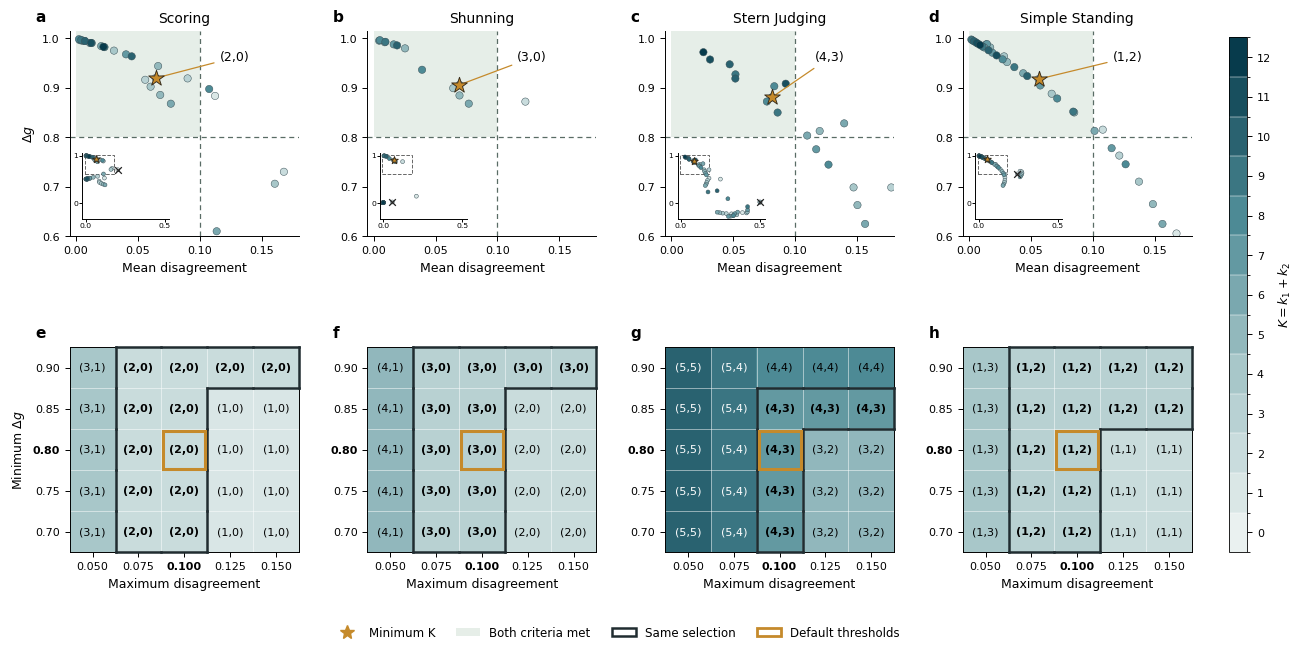

Saved eight panels and one combined figure in PDF and SVG.


In [6]:
def save_figure(fig, name):
    for extension in ['pdf', 'svg']:
        fig.savefig(FIGURES / f'{name}.{extension}', bbox_inches='tight', pad_inches=.03)

with mpl.rc_context(STYLE):
    for row, draw in enumerate([outcomes, threshold_map]):
        for col, norm_code in enumerate(NORMS):
            fig, ax = plt.subplots(figsize=(3.5, 2.9))
            fig.subplots_adjust(left=.20, right=.96, bottom=.23, top=.88)
            draw(ax, norm_code, CMAP)
            if row == 0:
                ax.set(title=NORM_NAMES[norm_code], xlabel='Mean disagreement', ylabel=r'$\Delta g$')
            else:
                ax.set(title=NORM_NAMES[norm_code], xlabel='Maximum disagreement', ylabel=r'Minimum $\Delta g$')
            save_figure(fig, f'panel_{"abcdefgh"[4 * row + col]}_{norm_code}')
            plt.close(fig)

    fig = plt.figure(figsize=(13.2, 6.6))
    grid = fig.add_gridspec(2, 4, left=.065, right=.915, bottom=.16, top=.95,
                          hspace=.54, wspace=.30)
    for col, norm_code in enumerate(NORMS):
        ax = fig.add_subplot(grid[0, col])
        outcomes(ax, norm_code, CMAP)
        ax.set(title=NORM_NAMES[norm_code], xlabel='Mean disagreement',
               ylabel=r'$\Delta g$' if col == 0 else '')
        ax.text(-.15, 1.045, 'abcd'[col], transform=ax.transAxes, fontsize=11, fontweight='bold')
        ax = fig.add_subplot(grid[1, col])
        threshold_map(ax, norm_code, CMAP)
        ax.set(xlabel='Maximum disagreement', ylabel=r'Minimum $\Delta g$' if col == 0 else '')
        ax.text(-.15, 1.045, 'efgh'[col], transform=ax.transAxes, fontsize=11, fontweight='bold')
    fig.legend(handles=[
        Line2D([], [], marker='*', ls='', ms=10, c=GOLD, label='Minimum K'),
        Patch(fc=ELIGIBLE, ec='none', label='Both criteria met'),
        Patch(fc='none', ec=OUTLINE, lw=1.8, label='Same selection'),
        Patch(fc='none', ec=GOLD, lw=2, label='Default thresholds'),
    ], loc='center', bbox_to_anchor=(.48, .038), ncol=4, frameon=False,
       fontsize=8.5, columnspacing=1.8)
    cax = fig.add_axes([.943, .16, .014, .78])
    colorbar = fig.colorbar(mpl.cm.ScalarMappable(norm=DEPTH_NORM, cmap=CMAP),
                           cax=cax, ticks=range(13), drawedges=True)
    colorbar.set_label(r'$K=k_1+k_2$')
    colorbar.dividers.set_color('white')
    colorbar.dividers.set_linewidth(.35)
    colorbar.outline.set_linewidth(.6)
    save_figure(fig, 'Extended_Data_Figure1_combined')
    plt.show()
    plt.close(fig)

assert len(list(FIGURES.glob('*.pdf'))) == len(list(FIGURES.glob('*.svg'))) == 9
print('Saved eight panels and one combined figure in PDF and SVG.')
